<a href="https://colab.research.google.com/github/ClassNeuralNetwork/IA-car-damage-detection/blob/main/modelo-EfficientNetB0/CarSegunda_Unidade_EfficientNetB0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Importação das bibliotecas

In [21]:
import kagglehub
import shutil
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import os
from PIL import Image
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from sklearn.metrics import confusion_matrix, f1_score, recall_score
import seaborn as sns
from google.colab import files
import shap

# Baixando o dataset

In [22]:
DATASET_PATH = kagglehub.dataset_download("anujms/car-damage-detection")

print("Path to dataset files:", DATASET_PATH)

Using Colab cache for faster access to the 'car-damage-detection' dataset.
Path to dataset files: /kaggle/input/car-damage-detection


In [23]:
def verificar_disposicao(diretorio_base):
    # Aponta para a pasta de treinamento dentro de data1a
    caminho_treino = os.path.join(
        diretorio_base, "data1a", "training"
    )

    print(f"Verificando pastas em: {caminho_treino}")

    # Mapeamento para nomes amigáveis em português
    nomes_classes = {
        "00-damage": "Carro com defeito",
        "01-whole": "Carro intacto"
    }

    if os.path.exists(caminho_treino):
        for pasta in sorted(os.listdir(caminho_treino)):
            caminho_completo = os.path.join(caminho_treino, pasta)

            if os.path.isdir(caminho_completo):
                total_arquivos = len(os.listdir(caminho_completo))
                nome_formatado = nomes_classes.get(pasta, pasta)

                print(
                    f"Classe: {nome_formatado} | "
                    f"Total de imagens: {total_arquivos}"
                )
    else:
        print(
            "Pasta de treinamento não encontrada "
            "no caminho especificado."
        )

verificar_disposicao(DATASET_PATH)



Verificando pastas em: /kaggle/input/car-damage-detection/data1a/training
Classe: Carro com defeito | Total de imagens: 920
Classe: Carro intacto | Total de imagens: 920


# Pré-processamento dos dados

In [24]:
IMG_HEIGHT = 224
IMG_WIDTH = 224
BATCH_SIZE = 32

# Caminhos das pastas de treino e validação
train_dir = os.path.join(
    DATASET_PATH, 'data1a', 'training'
)

validation_dir = os.path.join(
    DATASET_PATH, 'data1a', 'validation'
)

print("Conjunto de Treino (training):")

train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode='binary',
    shuffle=True
)

print("\nConjunto de Validação (validation):")

validation_dataset = tf.keras.utils.image_dataset_from_directory(
    validation_dir,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode='binary',
    shuffle=False
)

class_names = train_dataset.class_names

print(f"\nClasses identificadas: {class_names}")


Conjunto de Treino (training):
Found 1840 files belonging to 2 classes.

Conjunto de Validação (validation):
Found 460 files belonging to 2 classes.

Classes identificadas: ['00-damage', '01-whole']


# Função de normalização

In [25]:

def normalize(image, label):
    image = tf.cast(image, tf.float32)
    return image, label

train_dataset = train_dataset.map(normalize)
validation_dataset = validation_dataset.map(normalize)

print("Normalizados com sucesso!")


Normalizados com sucesso!


# Visualização das imagens

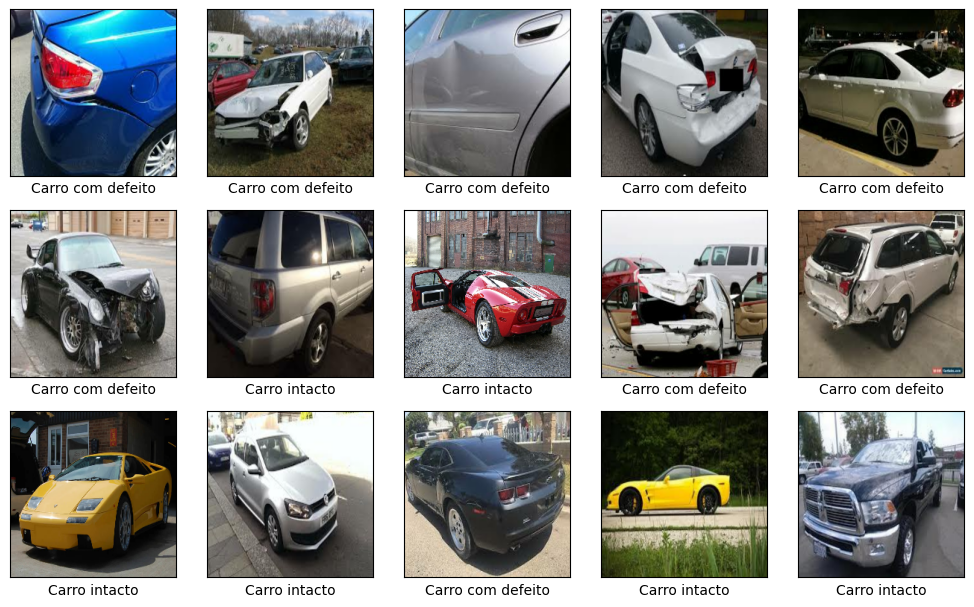

In [26]:

class_names = ['Carro com defeito', 'Carro intacto']

for images_batch, labels_batch in train_dataset.take(1):
    plt.figure(figsize=(10, 10))

    for i in range(min(15, len(images_batch))):
        plt.subplot(5, 5, i + 1)
        plt.xticks([])
        plt.yticks([])

        plt.imshow(
            images_batch[i].numpy().astype("uint8")
        )

        label_idx = int(labels_batch[i].numpy()[0])
        plt.xlabel(class_names[label_idx])

    plt.tight_layout()
    plt.show()


# Construindo a EfficientNetB0

In [27]:
base_model = EfficientNetB0(
    input_shape=(IMG_HEIGHT, IMG_WIDTH, 3),
    include_top=False,
    weights='imagenet',
)

base_model.trainable = True

for layer in base_model.layers[:-20]:
    layer.trainable = False

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3)),
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.01)),
    tf.keras.layers.Dropout(0.2),

    tf.keras.layers.Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.01)),
    tf.keras.layers.Dropout(0.2),

    tf.keras.layers.Dense(1, activation='sigmoid'),
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,230,180 (16.14 MB)

 Trainable params: 1,531,569 (5.84 MB)

 Non-trainable params: 2,698,611 (10.29 MB)

# Compilando o modelo

In [28]:
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
              loss='binary_crossentropy',
              metrics=['accuracy'])

# Treinando o modelo

In [29]:

# Configurando o Early Stopping
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=8,
    restore_best_weights=True
)

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=100,
    callbacks=[early_stopping]
)


Epoch 1/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 61s 582ms/step - accuracy: 0.8891 - loss: 2.3509 - val_accuracy: 0.9478 - val_loss: 1.0952
Epoch 2/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 4s 76ms/step - accuracy: 0.9554 - loss: 0.6873 - val_accuracy: 0.9348 - val_loss: 0.4940
Epoch 3/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 5s 83ms/step - accuracy: 0.9707 - loss: 0.2751 - val_accuracy: 0.9630 - val_loss: 0.2540
Epoch 4/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 4s 76ms/step - accuracy: 0.9685 - loss: 0.1717 - val_accuracy: 0.9413 - val_loss: 0.2411
Epoch 5/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 5s 77ms/step - accuracy: 0.9832 - loss: 0.1019 - val_accuracy: 0.9435 - val_loss: 0.2199
Epoch 6/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 5s 74ms/step - accuracy: 0.9832 - loss: 0.0833 - val_accuracy: 0.9478 - val_loss: 0.2442
Epoch 7/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 5s 74ms/step - accuracy: 0.9891 - loss: 0.0650 - val_accuracy: 0.9174 - val_loss: 0.3362
Epoch 8/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 4s 76ms/step - accuracy: 0.9864 - loss: 0.0654 - val_accuracy: 

# Gráficos de treinamento

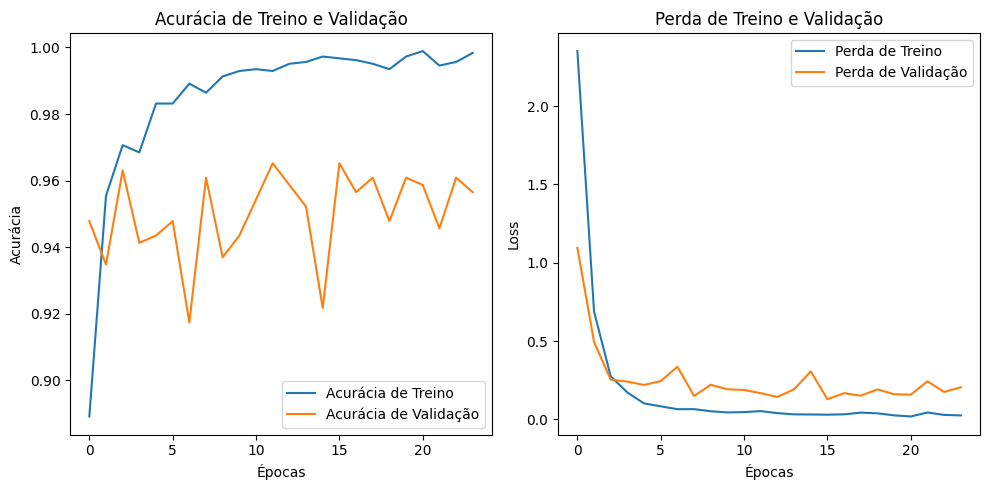

In [30]:
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Acurácia de Treino')
plt.plot(history.history['val_accuracy'], label='Acurácia de Validação')
plt.title('Acurácia de Treino e Validação')
plt.legend()
plt.xlabel('Épocas')
plt.ylabel('Acurácia')
plt.savefig('Acurácia_Treino_Validação.png', bbox_inches='tight', dpi=300)

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Perda de Treino')
plt.plot(history.history['val_loss'], label='Perda de Validação')
plt.title('Perda de Treino e Validação')
plt.legend()
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.savefig('Perda_Treino_Validação.png', bbox_inches='tight', dpi=300)
plt.legend()

plt.tight_layout()

## Salvando o Modelo

In [31]:
model.save('modelEfficientNetB0.keras')

In [32]:
model_carregado = tf.keras.models.load_model('modelEfficientNetB0.keras')

# Avaliação do modelo

In [33]:
from sklearn.metrics import classification_report

y_pred_prob = model.predict(validation_dataset)

y_pred = (y_pred_prob > 0.5).astype(int).flatten()

y_true = np.concatenate([y.numpy() for x, y in validation_dataset], axis=0).flatten()

relatorio = classification_report(y_true, y_pred, target_names=class_names)

print("Relatório de Classificação:\n")
print(relatorio)

15/15 ━━━━━━━━━━━━━━━━━━━━ 12s 479ms/step
Relatório de Classificação:

                   precision    recall  f1-score   support

Carro com defeito       0.97      0.96      0.97       230
    Carro intacto       0.96      0.97      0.97       230

         accuracy                           0.97       460
        macro avg       0.97      0.97      0.97       460
     weighted avg       0.97      0.97      0.97       460



# Matriz de confusão

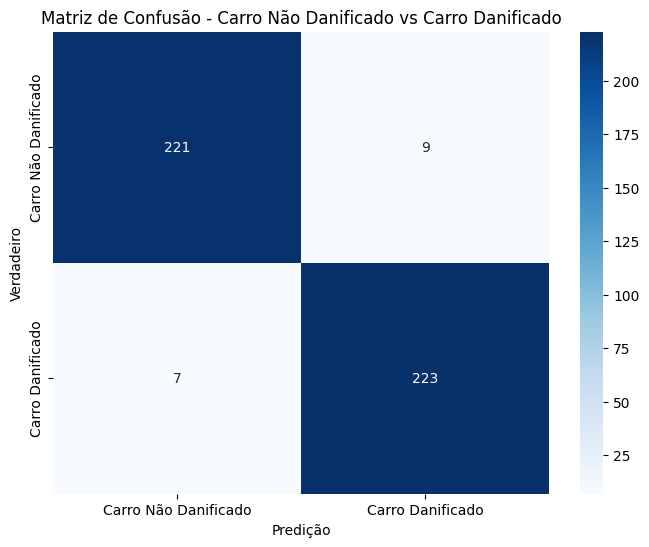

In [34]:
if "y_true" not in globals() or "y_pred" not in globals():
    y_pred_probs = []
    y_true = []

    for images, labels in train_dataset:
        predictions = model.predict(images, verbose=0)
        y_pred_probs.extend(predictions)
        y_true.extend(labels.numpy())

    # converte probabilidades em classes (0 ou 1)
    y_pred = [1 if p > 0.5 else 0 for p in y_pred_probs]

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=['Carro Não Danificado', 'Carro Danificado'], yticklabels=['Carro Não Danificado', 'Carro Danificado'])
plt.xlabel('Predição')
plt.ylabel('Verdadeiro')
plt.title('Matriz de Confusão - Carro Não Danificado vs Carro Danificado')
plt.savefig('confusion_matrix.png', bbox_inches='tight', dpi=300)
plt.show()

# IA Explicável — SHAP

In [35]:
for images, labels in train_dataset.take(1):
    background = images[:100].numpy()
    test_sample = images[:5].numpy()
    real_classes = labels[:5].numpy().astype(int).flatten()

pred = model.predict(test_sample)
pred_classes = (pred >= 0.5).astype(int).flatten()

print("Classes Preditas:", pred_classes)
print("Classes Reais:   ", real_classes)

1/1 ━━━━━━━━━━━━━━━━━━━━ 9s 9s/step
Classes Preditas: [0 1 0 0 0]
Classes Reais:    [0 1 0 0 0]


In [36]:
explainer = shap.GradientExplainer(model,background)

shap_values = explainer.shap_values(test_sample)

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_1538
Received: inputs=['Tensor(shape=(5, 224, 224, 3))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_1538
Received: inputs=['Tensor(shape=(50, 224, 224, 3))']
  warnings.warn(msg)



Classe prevista: Carro com defeito | Classe real: Carro com defeito


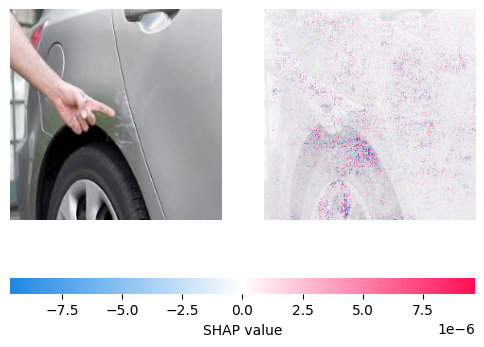


Classe prevista: Carro intacto | Classe real: Carro intacto


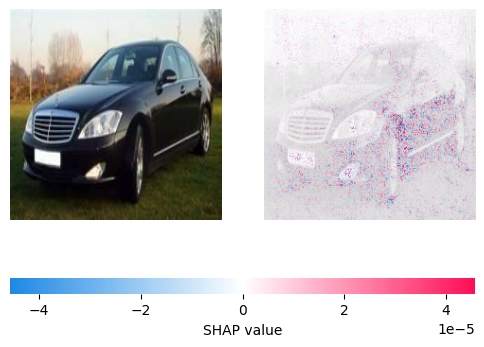


Classe prevista: Carro com defeito | Classe real: Carro com defeito


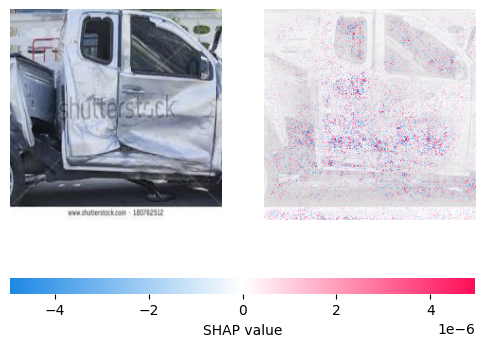


Classe prevista: Carro com defeito | Classe real: Carro com defeito


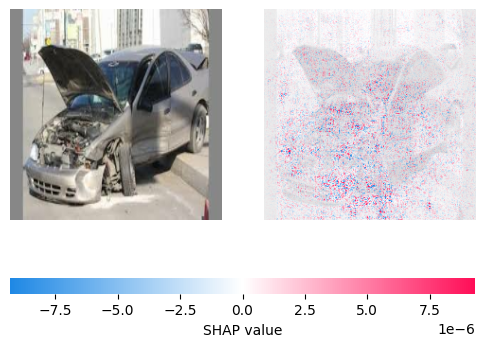


Classe prevista: Carro com defeito | Classe real: Carro com defeito


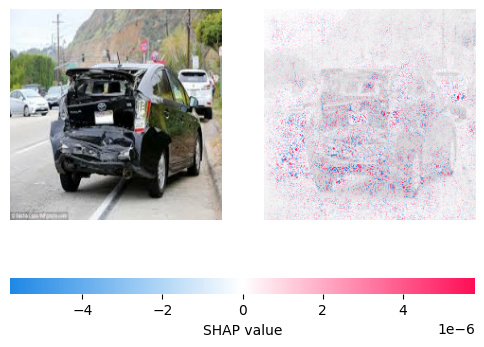

In [37]:
for i in range(len(test_sample)):
  print(
      f"\nClasse prevista: {class_names[pred_classes[i]]} "
      f"| Classe real: {class_names[real_classes[i]]}"
  )

  current_shap = shap_values[i, :, :, :, 0]
  current_img = test_sample[i, :, :, :]

  shap.image_plot(current_shap / 255.0,
      current_img / 255.0,
      show=True
  )